In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (accuracy_score, classification_report, mean_absolute_error,mean_squared_error,
                             confusion_matrix, precision_score, recall_score, 
                             f1_score, roc_auc_score, roc_curve)
import os
import sys

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
os.chdir('D:\Machine Learning\Datasets')

In [6]:
chem=pd.read_csv("ChemicalProcess.csv")

In [8]:
X,y=chem.drop('Yield',axis=1),chem['Yield']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25)
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Training samples: 123, Test samples: 53


Withouth StandardScaler 

Using Mean as Strategy in Simple Imputer

In [9]:
from sklearn.impute import SimpleImputer


imputer=SimpleImputer(strategy='mean')
scaler=StandardScaler()
X_train_impute=imputer.fit_transform(X_train)
X_test_impute=imputer.fit_transform(X_test)


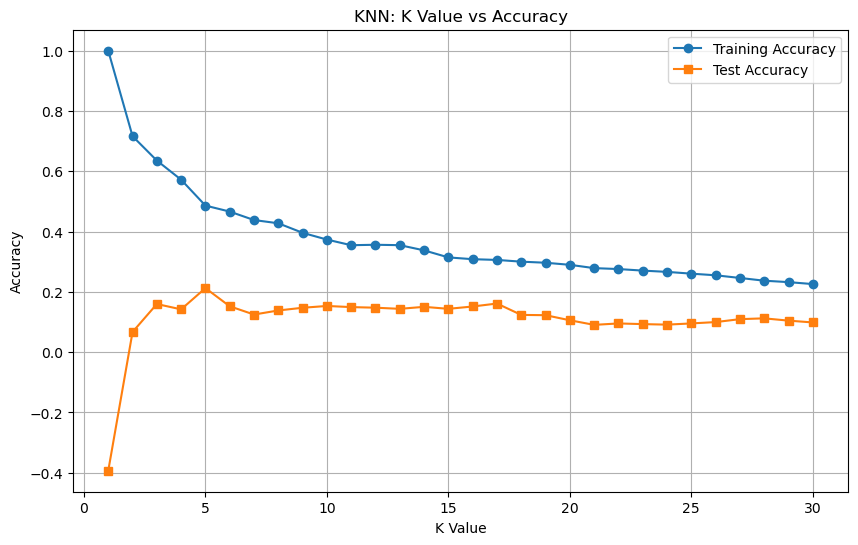

Optimal K value: 5


In [ ]:
k_values=range(1,31)
train_scores=[]
test_scores=[]

for k in k_values:
    knn_temp=KNeighborsRegressor(n_neighbors=k,)
    knn_temp.fit(X_train_impute,y_train)
    train_scores.append(knn_temp.score(X_train_impute, y_train))
    test_scores.append(knn_temp.score(X_test_impute, y_test)) 

# Plot K vs Accuracy
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, label='Training Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(test_scores)]
print(f"Optimal K value: {best_k}")

Using Median as Strategy for SimpleImputer

In [ ]:



imputer=SimpleImputer(strategy='median')
scaler=StandardScaler()
X_train_impute=imputer.fit_transform(X_train)
X_test_impute=imputer.fit_transform(X_test)


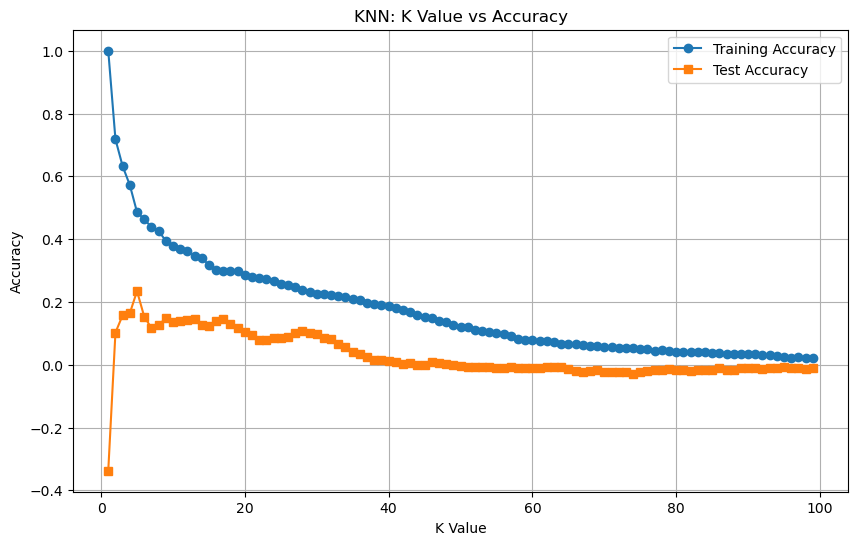

Optimal K value: 5


In [13]:
k_values=range(1,100)
train_scores=[]
test_scores=[]

for k in k_values:
    knn_temp=KNeighborsRegressor(n_neighbors=k)
    knn_temp.fit(X_train_impute,y_train)
    train_scores.append(knn_temp.score(X_train_impute, y_train))
    test_scores.append(knn_temp.score(X_test_impute, y_test)) 

# Plot K vs Accuracy
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, label='Training Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(test_scores)]
print(f"Optimal K value: {best_k}")

With StandardScaler 

In [ ]:

imputer=SimpleImputer(strategy='median')
scaler=StandardScaler()
X_train_impute=imputer.fit_transform(X_train)
X_test_impute=imputer.transform(X_test)
X_train_scaled=scaler.fit_transform(X_train_impute)
X_test_scaled=scaler.transform(X_test_impute)


Best k: 3.0, R² Score: 0.4046, MAE: 1.0401


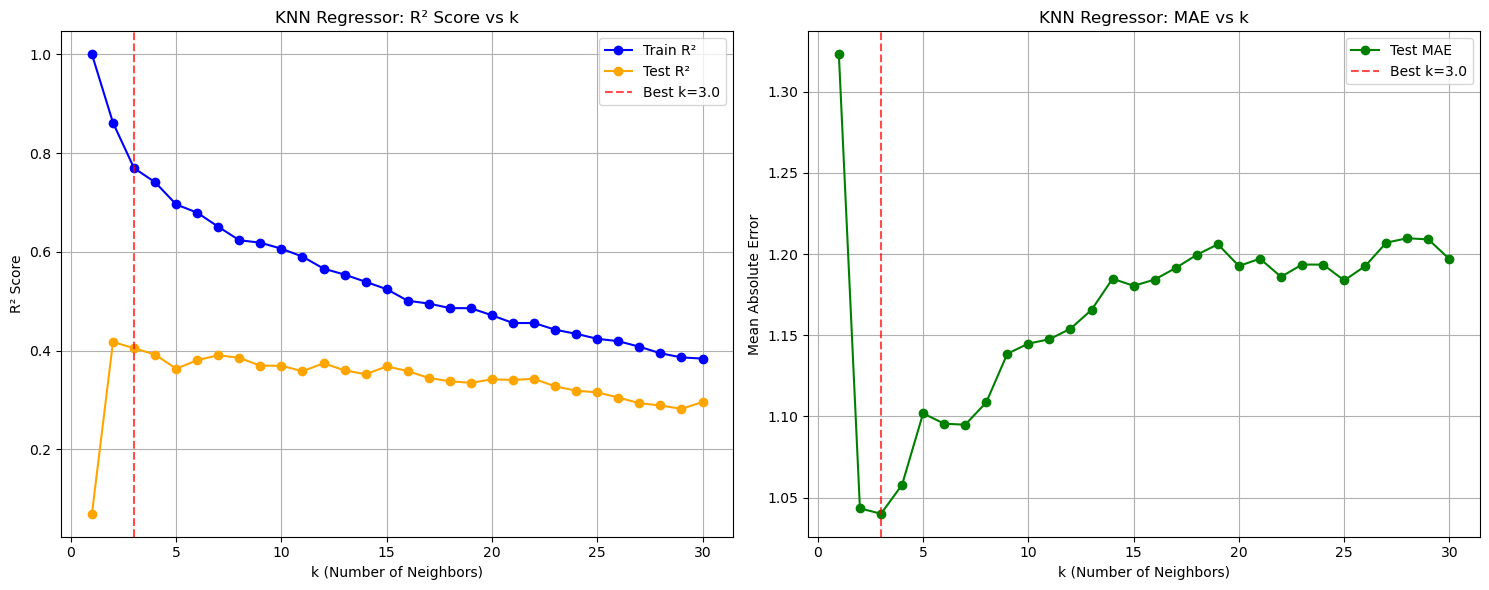


Top 5 models by MAE:
   k  r2_score       mae
2  3  0.404603  1.040063
1  2  0.417322  1.043396
3  4  0.391816  1.057830
6  7  0.390507  1.094879
5  6  0.380434  1.095566


In [29]:
k_values = range(1, 31)
train_scores = []
test_scores = []

for k in k_values:
    knn_temp = KNeighborsRegressor(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred = knn_temp.predict(X_test_scaled)
    train_scores.append([k, knn_temp.score(X_train_scaled, y_train)])
    test_scores.append([k, knn_temp.score(X_test_scaled, y_test), mean_absolute_error(y_test, y_pred)])

# Create DataFrames
df_train = pd.DataFrame(train_scores, columns=("k", "r2_score"))
df_test = pd.DataFrame(test_scores, columns=("k", "r2_score", "mae"))

# Sort by MAE (ascending since lower is better)
df_test_sorted = df_test.sort_values('mae', ascending=True)

# Print best k and scores
best_k = df_test_sorted.iloc[0]['k']
best_r2 = df_test_sorted.iloc[0]['r2_score']
best_mae = df_test_sorted.iloc[0]['mae']
print(f"Best k: {best_k}, R² Score: {best_r2:.4f}, MAE: {best_mae:.4f}")

# Create line charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# R² Score chart
axes[0].plot(df_train['k'], df_train['r2_score'], marker='o', label='Train R²', color='blue')
axes[0].plot(df_test['k'], df_test['r2_score'], marker='o', label='Test R²', color='orange')
axes[0].axvline(x=best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k={best_k}')
axes[0].set_xlabel('k (Number of Neighbors)')
axes[0].set_ylabel('R² Score')
axes[0].set_title('KNN Regressor: R² Score vs k')
axes[0].legend()
axes[0].grid(True)

# MAE chart
axes[1].plot(df_test['k'], df_test['mae'], marker='o', color='green', label='Test MAE')
axes[1].axvline(x=best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k={best_k}')
axes[1].set_xlabel('k (Number of Neighbors)')
axes[1].set_ylabel('Mean Absolute Error')
axes[1].set_title('KNN Regressor: MAE vs k')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Display sorted dataframe
print("\nTop 5 models by MAE:")
print(df_test_sorted.head())

In [32]:
from sklearn.pipeline import Pipeline

imputer=SimpleImputer(strategy='mean')
scaler=StandardScaler()
knn_temp=KNeighborsRegressor(n_neighbors=5)
pipe=Pipeline(steps=[('IMP',imputer),('SS',scaler),('KNN',knn_temp)])
pipe.fit(X_train,y_train)
y_pred=pipe.predict(X_test)
mean_absolute_error(y_test,y_pred)


1.101849056603773

In [33]:
pipe

Pipeline(steps=[('IMP', SimpleImputer()), ('SS', StandardScaler()),
                ('KNN', KNeighborsRegressor())])

In [35]:
imputers=['mean','median']
scaler=StandardScaler()
Ks=np.arange(1,21)
scores=[]
for k in Ks:
    for imp in imputers:
        imputer=SimpleImputer(strategy=imp)
        knn_temp=KNeighborsRegressor(n_neighbors=k)
        pipe=Pipeline(steps=[('IMP',imputer),('SS',scaler),('KNN',knn_temp)])
        pipe.fit(X_train,y_train)
        y_pred=pipe.predict(X_test)
        mae=mean_absolute_error(y_test,y_pred)
        scores.append([k,imp,mae])
scores_df=pd.DataFrame(scores,columns=('k','strategy','mae'))
scores_df.sort_values('mae').head(10)


,k,strategy,mae
4,3,mean,1.037673
5,3,median,1.040063
3,2,median,1.043396
2,2,mean,1.044623
6,4,mean,1.055047
7,4,median,1.057830
10,6,mean,1.085535
12,7,mean,1.086873
13,7,median,1.094879
11,6,median,1.095566
